# Laboratorio · Predecir propinas con Python
**Regresión lineal · Ejercicio individual**

**Dataset:** `tips.csv`, 244 cuentas de restaurante. [Ver dataset en Kaggle](https://www.kaggle.com/datasets/sakshisatre/tips-dataset).

**Problema:** estimar `tip` (propina en USD) a partir de `total_bill` (cuenta en USD) y después comprobar si `size` (número de personas) aporta valor.

**Instrucciones:** ejecutar las actividades en orden, completar las celdas de código y responder las preguntas con resultados propios. El archivo CSV debe estar junto al notebook.

## 01 · Explorar el CSV
**Objetivo.** Cargar `tips.csv` y mostrar **cinco filas**, dimensiones, valores faltantes y resumen numérico.

*Pista:* `pd.read_csv()`, `.head()`, `.shape`, `.isna().sum()`, `.describe()`.

**Resultado esperado:** Una tabla y el resumen inicial.

In [4]:
import pandas as pd

datos = pd.read_csv("tips.csv")

print("Filas y columnas:", datos.shape)
display(datos.head())

print("Valores faltantes:")
print(datos.isna().sum())

display(datos.describe())

Filas y columnas: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Valores faltantes:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## 02 · Separar entradas y objetivo
**Objetivo.** Crear `X` con la cuenta total (`total_bill`) y `y` con la propina real (`tip`). Mostrar sus primeras filas y dimensiones.

*Pista:* `datos[["total_bill"]]` devuelve una tabla; `datos["tip"]` devuelve la serie objetivo.

**Resultado esperado:** Entradas y objetivos claramente identificados.

In [5]:
X = datos[["total_bill"]]
y = datos["tip"]

print("Forma de X:", X.shape, "| Forma de y:", y.shape)
display(pd.DataFrame({
    "X: Cuenta total": X["total_bill"],
    "y: propina": y,
}).head())

Forma de X: (244, 1) | Forma de y: (244,)


,X: Cuenta total,y: propina
0,16.99,1.01
1,10.34,1.66
2,21.01,3.50
3,23.68,3.31
4,24.59,3.61


## 03 · Crear entrenamiento y prueba
**Objetivo.** Reservar el 25 % de los registros para evaluar, usando `random_state=42`. Mostrar cuántas filas quedan en cada conjunto.

*Pista:* `train_test_split()` del módulo `sklearn.model_selection`.

**Resultado esperado:** Tamaños de `X_train`, `X_test`, `y_train`, `y_test`.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
)

print(f"Entrenamiento: {len(X_train)} filas | Prueba: {len(X_test)} filas")

print("ENTRENAMIENTO: X_train + y_train")
display(pd.DataFrame({
    "X_train: cuenta total": X_train["total_bill"],
    "y_train: propina": y_train,
}).head())

print("PRUEBA: X_test + y_test")
display(pd.DataFrame({
    "X_test: cuenta total": X_test["total_bill"],
    "y_test: propina": y_test,
}).head())

Entrenamiento: 183 filas | Prueba: 61 filas
ENTRENAMIENTO: X_train + y_train


,X_train: cuenta total,y_train: propina
115,17.31,3.50
181,23.33,5.65
225,16.27,2.50
68,20.23,2.01
104,20.92,4.08


PRUEBA: X_test + y_test


,X_test: cuenta total,y_test: propina
24,19.82,3.18
6,8.77,2.00
153,24.55,2.00
211,25.89,5.16
198,13.00,2.00


## 04 · Entrenar y predecir
**Objetivo.** Crear una regresión, ajustarla con entrenamiento y predecir las propinas del conjunto de prueba. Mostrar cinco predicciones.

*Pista:* `LinearRegression()`, `.fit()`, `.predict()`.

**Resultado esperado:** Cinco importes estimados.

In [7]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()
modelo.fit(X_train, y_train)
pred = modelo.predict(X_test)

print(f"Pendiente: {modelo.coef_[0]:,.2f}")
print(f"Intercepto: {modelo.intercept_:,.2f}")
display(pd.DataFrame({
    "Real": y_test.to_numpy(),
    "Predicho": pred,
}).head())

Pendiente: 0.11
Intercepto: 0.86


,Real,Predicho
0,3.18,3.030194
1,2.00,1.821164
2,2.00,3.547725
3,5.16,3.694340
4,2.00,2.283987


## 05 · Evaluar los errores
**Objetivo.** Calcular **MAE, MSE, RMSE y R²** sobre los datos de prueba e imprimir sus valores.

*Pista:* `sklearn.metrics`; para RMSE se puede usar `mse ** 0.5`.

**Resultado esperado:** Cuatro indicadores numéricos.

In [8]:
from sklearn.metrics import (
    mean_absolute_error,
    median_absolute_error,
    mean_absolute_percentage_error,
)

mae = mean_absolute_error(y_test, pred)
medae = median_absolute_error(y_test, pred)
mape = mean_absolute_percentage_error(y_test, pred) * 100

print(f"MAE:   {mae:,.2f} unidades de propina")
print(f"MedAE: {medae:,.2f} unidades de propina")
print(f"MAPE:  {mape:.2f} %")

MAE:   0.65 unidades de propina
MedAE: 0.47 unidades de propina
MAPE:  25.87 %


In [9]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, pred)
rmse = mse ** 0.5

print(f"MSE:  {mse:,.2f} (propina^2)")
print(f"RMSE: {rmse:,.2f} (propina)")

MSE:  0.74 (propina^2)
RMSE: 0.86 (propina)


## 06 · Graficar datos y predicción
**Objetivo.** Construir una tabla de cinco valores reales y predichos. Dibujar los puntos reales y la recta del modelo, con nombres en los ejes y leyenda.

*Pista:* `pd.DataFrame()`, `plt.scatter()`, `plt.plot()`; ordenar X solo para dibujar la línea.

**Resultado esperado:** Tabla comparativa y gráfico.

,Real,Predicho
0,3.18,3.030194
1,2.00,1.821164
2,2.00,3.547725
3,5.16,3.694340
4,2.00,2.283987


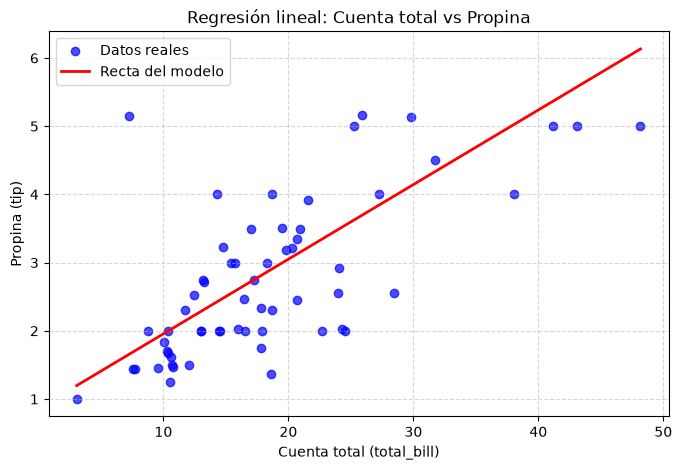

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

tabla_comparativa= pd.DataFrame({"Real": y_test.to_numpy(), "Predicho": pred})
display(tabla_comparativa.head(5))

plt.figure(figsize=(8, 5))

plt.scatter(X_test, y_test, color='blue', alpha=0.7, label='Datos reales')

if isinstance(X_test, pd.DataFrame):
    X_test_ordenado = X_test.sort_values(by="total_bill")
else:
    X_test_ordenado = X_test.sort_values()

pred_ordenado = modelo.predict(X_test_ordenado)

plt.plot(X_test_ordenado, pred_ordenado, color='red', linewidth=2, label='Recta del modelo')

plt.xlabel("Cuenta total (total_bill)")
plt.ylabel("Propina (tip)")
plt.title("Regresión lineal: Cuenta total vs Propina")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 07 · Inspeccionar residuos
**Objetivo.** Calcular `real − predicho`; graficar los residuos contra las predicciones, con una línea horizontal en cero.

*Pista:* `.to_numpy()`, `plt.scatter()`, `plt.axhline(0)`.

**Resultado esperado:** Gráfico de residuos.

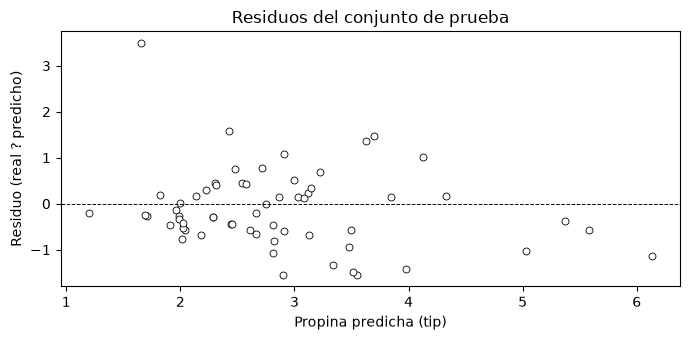

MAE:  0.65 ? 328.52
RMSE: 0.86 ? 2560.72
R^2:   0.44  |  R^2 extremo:  -4928710.042


In [15]:
from sklearn.metrics import r2_score

residuos = y_test.to_numpy() - pred

plt.figure(figsize=(7, 3.5))
plt.scatter(
    pred,
    residuos,
    s=25,
    facecolors="white",
    edgecolors="black",
    linewidths=0.6,
)
plt.axhline(0, color="black", linewidth=0.7, linestyle="--")
plt.xlabel("Propina predicha (tip)")
plt.ylabel("Residuo (real ? predicho)")
plt.title("Residuos del conjunto de prueba")
plt.tight_layout()
plt.show()

# Introduce un error extremo en una sola predicción.
pred_extremo = pred.copy()
pred_extremo[0] += 20000

print(
    "MAE: ",
    round(mae, 2),
    "?",
    round(mean_absolute_error(y_test, pred_extremo), 2),
)
print(
    "RMSE:",
    round(rmse, 2),
    "?",
    round(mean_squared_error(y_test, pred_extremo) ** 0.5, 2),
)
print(
    "R^2:  ",
    round(r2_score(y_test, pred), 3),
    " |  R^2 extremo: ",
    round(r2_score(y_test, pred_extremo), 3),
)

## 08 · Comparar una y dos entradas
**Objetivo.** Entrenar un segundo modelo usando `total_bill` y `size` juntos. Comparar **MAE, RMSE y R²** con el modelo inicial.

*Pista:* Definir `X2` con dos columnas y repetir la partición con el mismo `random_state`.

**Resultado esperado:** Comparación numérica de ambos modelos.

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Calcular métricas del Modelo 1 (1 variable: total_bill)
mae = mean_absolute_error(y_test, pred)
rmse = mean_squared_error(y_test, pred) ** 0.5
r2 = r2_score(y_test, pred)

# 2. Calcular métricas del Modelo 2 (2 variables: total_bill y size)
# (Asegúrate de que 'pred2' o 'pred_modelo2' sea la variable con tus predicciones del Modelo 2)
mae2 = mean_absolute_error(y_test, pred2)
rmse2 = mean_squared_error(y_test, pred2) ** 0.5
r2_2 = r2_score(y_test, pred2)

# 3. Imprimir comparación
print("--- COMPARACIÓN DE MODELOS ---")
print("Modelo 1 (1 variable: total_bill):")
print(f"  - MAE:  {mae:.2f}")
print(f"  - RMSE: {rmse:.2f}")
print(f"  - R²:   {r2:.2f}\n")  # El \n va fuera de la llave

print("Modelo 2 (2 variables: total_bill y size):")
print(f"  - MAE:  {mae2:.2f}")
print(f"  - RMSE: {rmse2:.2f}")
print(f"  - R²:   {r2_2:.2f}")

--- COMPARACIÓN DE MODELOS ---
Modelo 1 (1 variable: total_bill):
  - MAE:  0.65
  - RMSE: 0.86
  - R²:   0.44

Modelo 2 (2 variables: total_bill y size):
  - MAE:  0.67
  - RMSE: 0.88
  - R²:   0.42


## Preguntas de desarrollo
Responder con los resultados obtenidos y, cuando corresponda, hacer referencia a los gráficos.

1. ¿Qué información contiene `X` y cuál es el objetivo `y`? ¿Qué cambia en la entrada cuando se agrega `size`?
2. ¿Cómo interpretar el MAE del primer modelo en **dólares de propina**? Dar un ejemplo de su significado.
3. ¿Qué diferencia existe entre MAE y RMSE? ¿Qué sugiere que RMSE sea mayor?
4. ¿Qué representa el R² obtenido? Explicar por qué **no** es un porcentaje de predicciones correctas.
5. ¿Qué se observa en el gráfico de residuos? ¿Hay valores especialmente alejados de cero?
6. ¿El modelo con dos entradas mejora los resultados en test? Justificar con MAE, RMSE y R² y proponer una explicación posible.

### Respuestas

**1.** "X" contiene el valor independiente de la función y que en este caso es la cuenta total (total_bill) e "y" es el valor dependiente y que es la variable que se quiere determinar. Cuando a la entrada se le agrega "size" la matriz de característica pasa a ser bidimensional, que en cierto modo esto nos entrega mas información, y con más información, mejores sera los resultados obtenidos.

**2.** El MAE es el promedio de las distancias absolutas entre la cuenta total de los clientes y la propina que ellos dejan, en este caso nuestro MAE fue de 0.65 dolares, esto signifoca que la propina de una mesa (basado en la cuenta total), el modelo se equivoca 0.65 dolares ya sea 0.65 dolares más o menos.

**3.** El MAE y el RMSE de diferencian en que el MAE calcula el promedio de las diferencias absolutas tratando todos los errores por igual, en cambio, el RMSE eleva al cuadraro los errores y de ahí, recién promedia y luego saca la raíz cuadrada, esto le otorga un mayor peso a los errores grandes. Que el RMSE sea mayor nos puede indicar la existencia de valores atípicos.

**4.** R^2 indica la proporción de variabilidad de los valores reales, es decir que tan alejados estan los datos reales de la media. Y no es un porcentaje de predicciones correctas porque el R^2 no indica que que "x" valores estan acertados, sino que el modelo es capaz de explicar el 45% de la variabilidad o dispersión de los datos.

**5.** En el gráfico de los residuos se pueden observar que existen valores que se acercan a cero, pero tambien podemos observar que existen varios datos que si se alejan bastante del 0, y que existan varios valores alejados de 0 nos indica que son datos atipicos, ya sean propinas inusualmente altas o inusualmete bajas dependiento del punto.

**6.** Un modelo con dos entradas, por lo general, si se observa una mejora en las métricas y en su mayoria disminuyen el MAE y el RMSE, y esto ocurre porque al tener mas características en la base de datos, tenemos mayor información que complementa (en este caso) la cuenta total, por ejemplo se podrian asociar la cantidad de personas en una mesa, ya que en su mayoria, las mesas con una mayor cuenta total, se asocian con una mayor canidad de personas, y dada esta información el algoritmo puede captar de mejor manera la complejidad de los datos.